# Tugas: Klasifikasi Kematangan Buah (Perbandingan Color Space)
Di dalam eksperimen ini, kita akan membandingkan bagaimana ruang warna (color space) **RGB/Grayscale**, **HSV**, dan **CIELAB** merepresentasikan berbagai tahapan kematangan buah pisang (mentah/unripe, matang/ripe, terlalu matang/overripe).

**Tujuan**: Menemukan *color space* mana yang menonjolkan fitur terbaik untuk membedakan ketiga kelas tersebut, lalu mempraktikkan logika klasifikasi berbasis persentase piksel (Rule-Based Classification).

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

def show_three(img1, img2, img3, title1="Unripe", title2="Ripe", title3="Overripe", cmap=None):
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axs, [img1, img2, img3], [title1, title2, title3]):
        if cmap:
            ax.imshow(img, cmap=cmap)
        else:
            ax.imshow(img)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 1. Load Data Gambar Asli
Kita muat dataset gambar pisang dan konversi BGR ke RGB agar Matplotlib menampilkannya dengan warna yang benar.

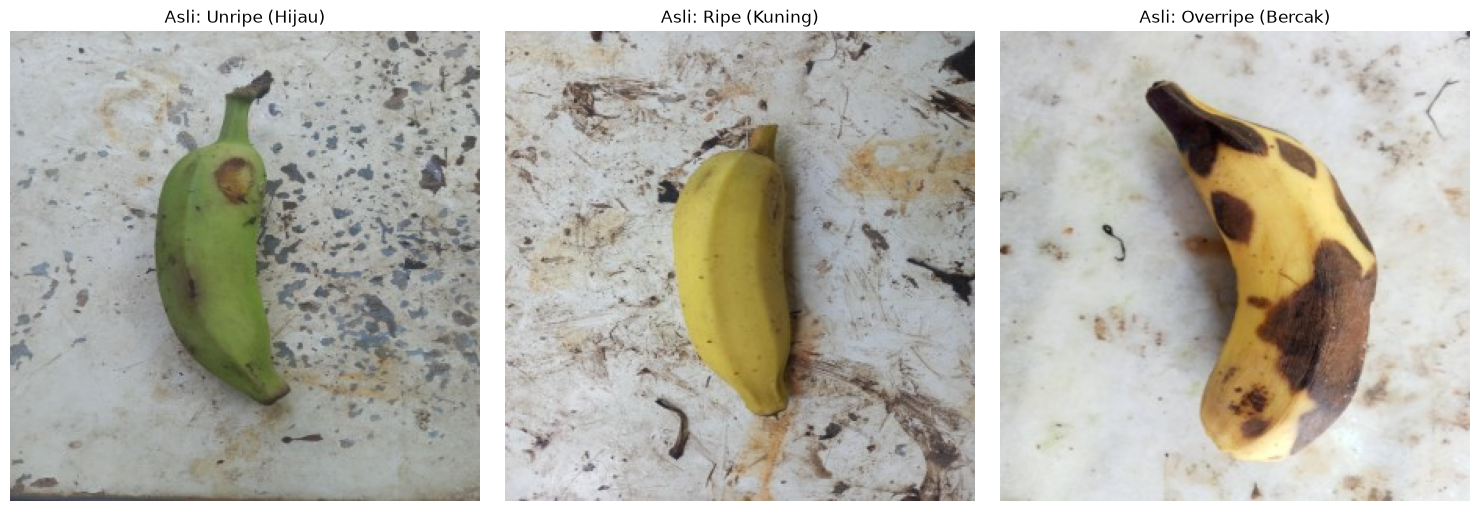

In [18]:
# Load gambar
unripe = cv2.imread('../assets/banana_unripe_117.jpg')
ripe = cv2.imread('../assets/banana_ripe_117.jpg')
overripe = cv2.imread('../assets/banana_overripe.jpg')

if unripe is None or ripe is None or overripe is None:
    print("Error: Gagal memuat gambar. Cek kembali path filenya.")
else:
    # Konversi ke RGB
    unripe_rgb = cv2.cvtColor(unripe, cv2.COLOR_BGR2RGB)
    ripe_rgb = cv2.cvtColor(ripe, cv2.COLOR_BGR2RGB)
    overripe_rgb = cv2.cvtColor(overripe, cv2.COLOR_BGR2RGB)

    show_three(unripe_rgb, ripe_rgb, overripe_rgb, "Asli: Unripe (Hijau)", "Asli: Ripe (Kuning)", "Asli: Overripe (Bercak)")

### 2. Flow 1: RGB -> Grayscale -> Binary Thresholding
Mari kita lihat apakah intensitas Grayscale bisa membedakan kematangan. Kita gunakan *inverted binary threshold* untuk mendeteksi "bercak hitam/gelap".

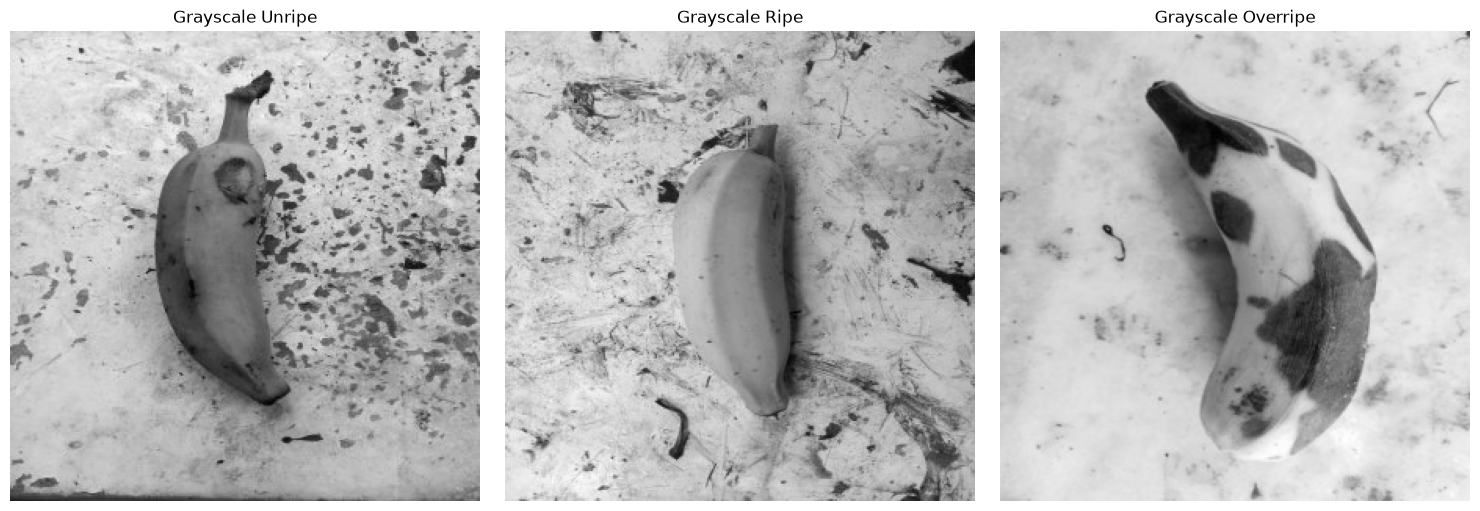

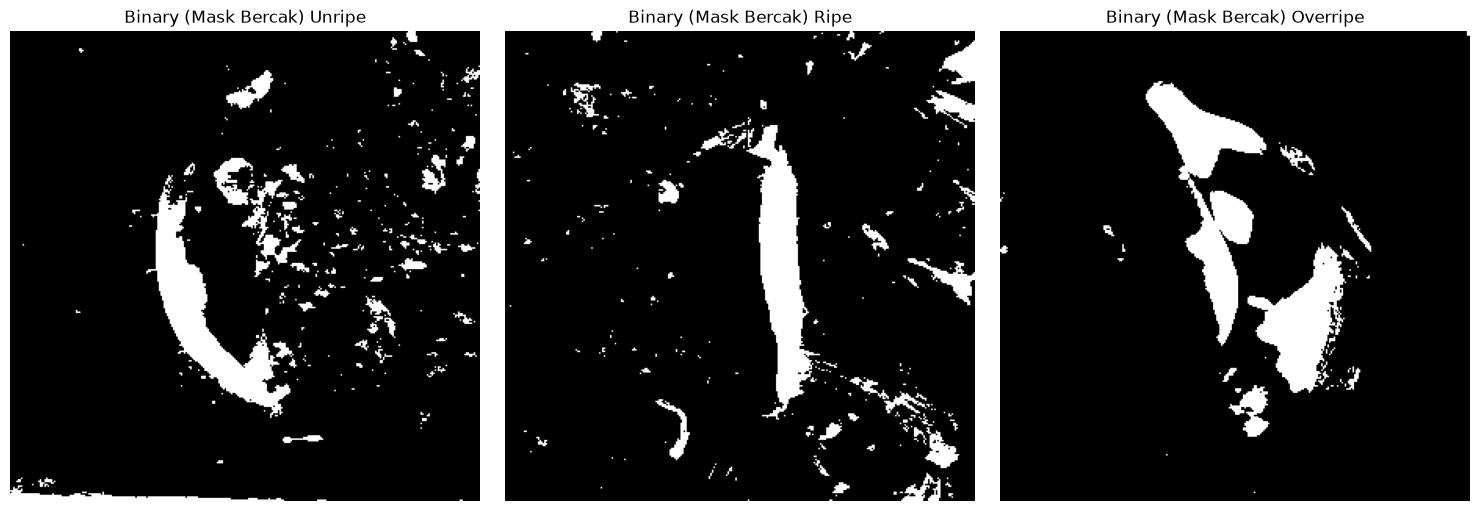

In [19]:
if unripe is not None:
    # Konversi ke Grayscale
    unripe_gray = cv2.cvtColor(unripe, cv2.COLOR_BGR2GRAY)
    ripe_gray = cv2.cvtColor(ripe, cv2.COLOR_BGR2GRAY)
    overripe_gray = cv2.cvtColor(overripe, cv2.COLOR_BGR2GRAY)

    show_three(unripe_gray, ripe_gray, overripe_gray, "Grayscale Unripe", "Grayscale Ripe", "Grayscale Overripe", cmap='gray')

    # Binary Thresholding: Piksel yang lebih gelap dari 100 menjadi putih (255), sisanya hitam (0)
    _, thresh_unripe = cv2.threshold(unripe_gray, 100, 255, cv2.THRESH_BINARY_INV)
    _, thresh_ripe = cv2.threshold(ripe_gray, 100, 255, cv2.THRESH_BINARY_INV)
    _, thresh_overripe = cv2.threshold(overripe_gray, 100, 255, cv2.THRESH_BINARY_INV)

    show_three(thresh_unripe, thresh_ripe, thresh_overripe, "Binary (Mask Bercak) Unripe", "Binary (Mask Bercak) Ripe", "Binary (Mask Bercak) Overripe", cmap='gray')

**Observasi (Grayscale/Binary)**: 
Bisa dilihat bahwa teknik ini **SANGAT SUKSES** mengisolasi bercak hitam pada pisang *overripe*! Namun, gagal total membedakan antara pisang hijau (unripe) dan kuning (ripe) karena nilai terang/gelapnya mirip.

### 3. Flow 2: RGB -> HSV (Hue, Saturation, Value)
HSV memisahkan warna murni (Hue) dari pencahayaan. Mari fokus ke *channel* **Hue**.

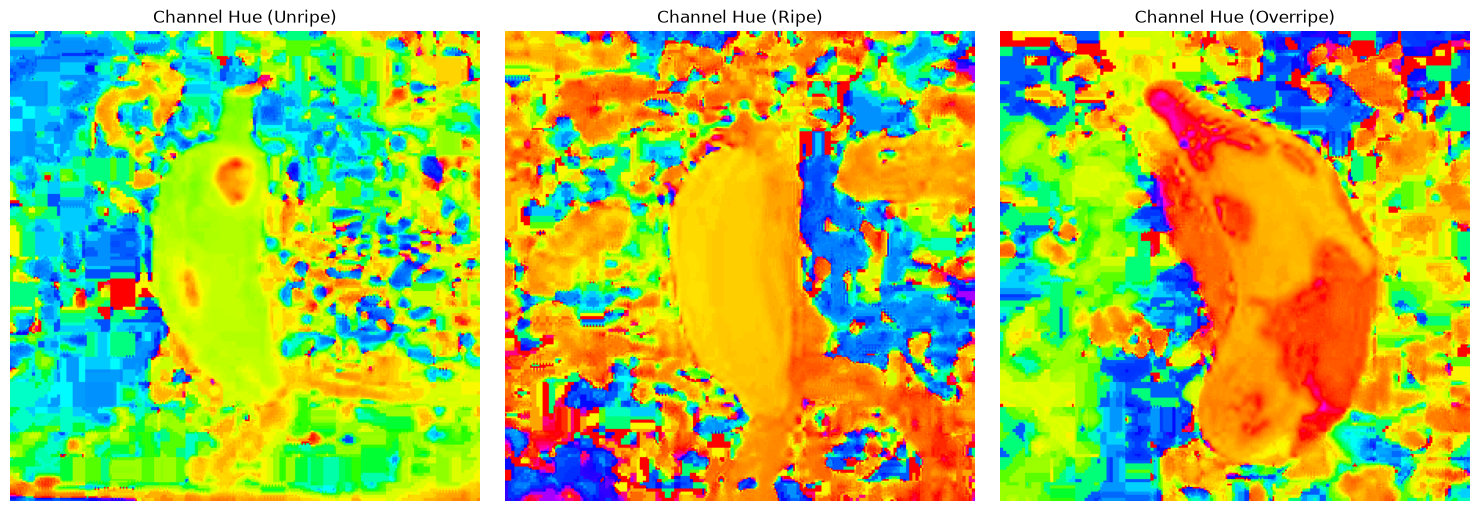

In [20]:
if unripe is not None:
    # Konversi ke HSV
    unripe_hsv = cv2.cvtColor(unripe, cv2.COLOR_BGR2HSV)
    ripe_hsv = cv2.cvtColor(ripe, cv2.COLOR_BGR2HSV)
    overripe_hsv = cv2.cvtColor(overripe, cv2.COLOR_BGR2HSV)

    # Ekstrak channel Hue (Indeks 0)
    h_unripe = unripe_hsv[:,:,0]
    h_ripe = ripe_hsv[:,:,0]
    h_overripe = overripe_hsv[:,:,0]

    show_three(h_unripe, h_ripe, h_overripe, "Channel Hue (Unripe)", "Channel Hue (Ripe)", "Channel Hue (Overripe)", cmap='hsv')

**Observasi (HSV)**: 
Sumbu Hue dengan sangat jelas memisahkan kelompok spektrum warna hijau pada pisang Unripe dengan kelompok warna kuning kemerahan pada pisang Ripe.

### 4. Flow 3: RGB -> CIELAB (L*a*b*)
Meniru mata manusia.
- **L***: Lightness (kecerahan)
- **a***: Sumbu Hijau (negatif) ke Merah (positif)
- **b***: Sumbu Biru (negatif) ke Kuning (positif)

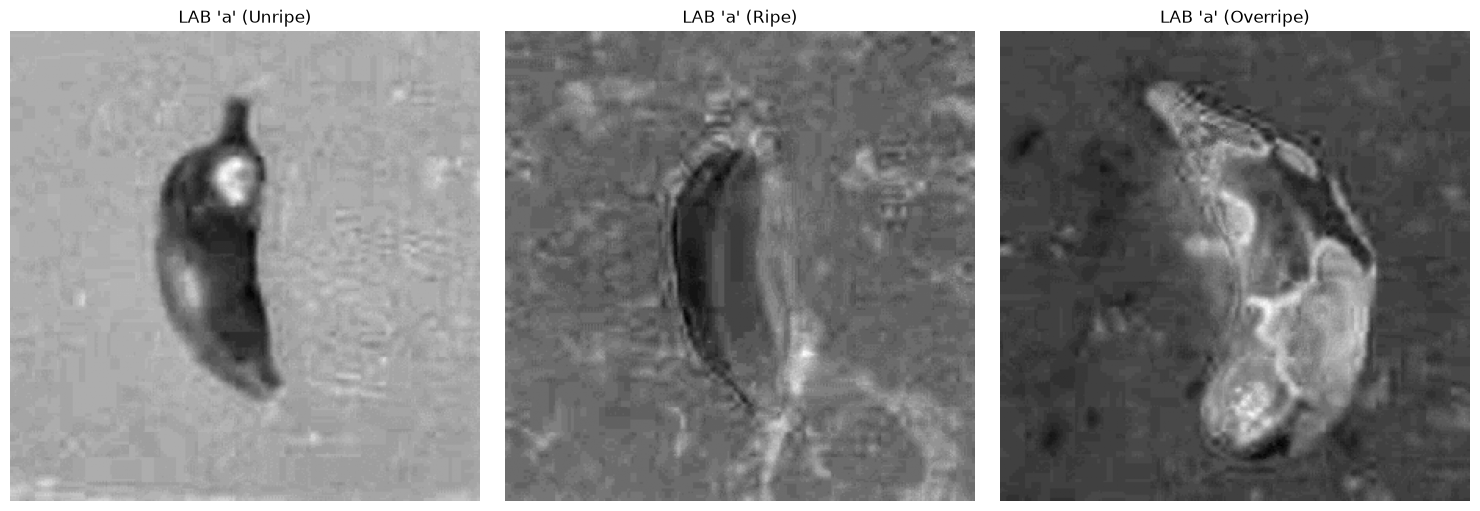

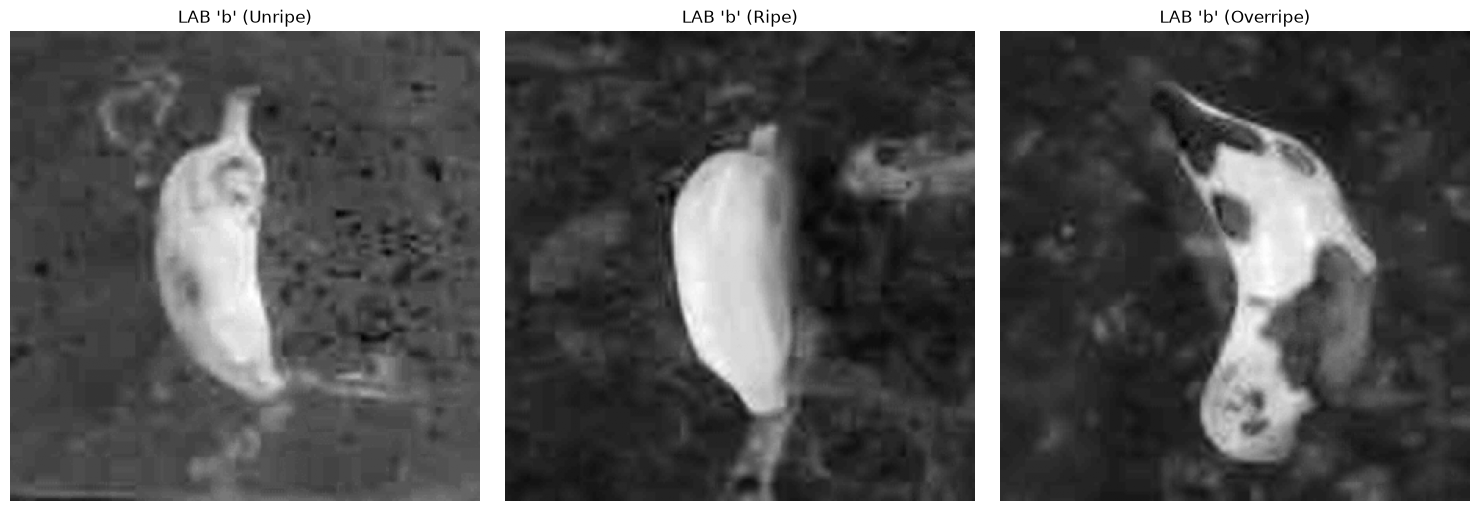

In [21]:
if unripe is not None:
    # Konversi ke LAB
    unripe_lab = cv2.cvtColor(unripe, cv2.COLOR_BGR2LAB)
    ripe_lab = cv2.cvtColor(ripe, cv2.COLOR_BGR2LAB)
    overripe_lab = cv2.cvtColor(overripe, cv2.COLOR_BGR2LAB)

    # Ekstrak channel 'a' (Hijau ke Merah)
    # Di OpenCV, nilai digeser 0-255. Nilai kecil (<128) berarti cenderung Hijau.
    a_unripe = unripe_lab[:,:,1]
    a_ripe = ripe_lab[:,:,1]
    a_overripe = overripe_lab[:,:,1]

    show_three(a_unripe, a_ripe, a_overripe, "LAB 'a' (Unripe)", "LAB 'a' (Ripe)", "LAB 'a' (Overripe)", cmap='gray')
    
    # Ekstrak channel 'b' (Biru ke Kuning)
    # Nilai besar (>128) berarti cenderung Kuning.
    b_unripe = unripe_lab[:,:,2]
    b_ripe = ripe_lab[:,:,2]
    b_overripe = overripe_lab[:,:,2]
    
    show_three(b_unripe, b_ripe, b_overripe, "LAB 'b' (Unripe)", "LAB 'b' (Ripe)", "LAB 'b' (Overripe)", cmap='gray')

### 5. Praktik Final: Full Klasifikasi Menggunakan Kombinasi CIELAB & Kontur
Metode ROI elips sebelumnya bekerja baik, namun kurang dinamis jika posisi pisang bergeser. Sekarang kita akan menggunakan potensi penuh dari **Color Space CIELAB** untuk melakukan segmentasi (masking) pisang secara otomatis, tak peduli apapun backgroundnya!

**Logika Masking Tingkat Lanjut:**
1. **Cari Pisang**: Kita buat *mask* kuning (Channel b* > 150) dan *mask* hijau (Channel a* < 120). Gabungan keduanya akan mendeteksi area kulit pisang dan mengabaikan *background* tanah/pasir.
2. **Isi Lubang (Fill Contours)**: Bercak hitam tidak terdeteksi oleh mask kuning/hijau (sehingga bolong-bolong). Kita gunakan fungsi `cv2.findContours` untuk mencari batas terluar pisang dan menambal/mengisi bolong tersebut. Ini menjadi **Mask Pisang Utuh**.
3. **Deteksi Bercak & Hijau**: Di dalam *Mask Pisang Utuh*, kita hitung rasio piksel bercak gelap (L < 100) dan rasio piksel hijau (a < 120).
4. **Pohon Keputusan (Decision Tree)**: 
   - Jika `Rasio Bercak > 5%` ➡️ OVERRIPE
   - Jika `Rasio Hijau > 15%` ➡️ UNRIPE
   - Sisanya ➡️ RIPE

In [ ]:
def advanced_classification(image, name="Pisang"):
    # Konversi ke CIELAB
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    
    # 1. Mask Warna Pisang (Hijau atau Kuning)
    _, mask_green = cv2.threshold(a, 120, 255, cv2.THRESH_BINARY_INV) # a < 120 (Hijau)
    _, mask_yellow = cv2.threshold(b, 150, 255, cv2.THRESH_BINARY)    # b > 150 (Kuning)
    skin_mask = cv2.bitwise_or(mask_green, mask_yellow)
    
    # 2. Tambal Masking dengan Kontur (Untuk memasukkan area bercak hitam)
    contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled_banana_mask = np.zeros_like(skin_mask)
    if contours:
        # Ambil 2 kontur terbesar (jaga-jaga jika pisang terputus oleh bercak besar)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        for c in contours[:2]:
            if cv2.contourArea(c) > 500:
                cv2.drawContours(filled_banana_mask, [c], -1, 255, -1) # -1 berarti fill (isi penuh)
                
    # 3. Hitung Luas Fitur di DALAM pisang
    _, dark_mask = cv2.threshold(l, 100, 255, cv2.THRESH_BINARY_INV) # Bercak gelap (L < 100)
    spot_mask = cv2.bitwise_and(dark_mask, filled_banana_mask)
    green_inside = cv2.bitwise_and(mask_green, filled_banana_mask)
    
    total_banana = cv2.countNonZero(filled_banana_mask)
    total_spot = cv2.countNonZero(spot_mask)
    total_green = cv2.countNonZero(green_inside)
    
    if total_banana == 0:
        print(f"{name}: Gagal mendeteksi pisang.")
        return
        
    ratio_spot = (total_spot / total_banana) * 100
    ratio_green = (total_green / total_banana) * 100
    
    # Visualisasi Masking Prosesnya
    show_three(skin_mask, filled_banana_mask, spot_mask, 
               f"Tahap 1: Deteksi Kulit ({name})", "Tahap 2: Pisang Utuh (Diisi)", "Tahap 3: Deteksi Bercak", cmap='gray')
    
    # 4. Pohon Keputusan (Rule-Based)
    if ratio_spot > 5.0:
        status = "OVERRIPE (Terlalu Matang)"
    elif ratio_green > 15.0:
        status = "UNRIPE (Mentah)"
    else:
        status = "RIPE (Matang Sempurna)"
        
    print(f"--- Laporan Klasifikasi: {name} ---")
    print(f"Luas Total Pisang : {total_banana} px")
    print(f"Rasio Area Hijau  : {ratio_green:.2f}%")
    print(f"Rasio Area Bercak : {ratio_spot:.2f}%")
    print(f"KESIMPULAN KELAS  : {status}")
    print("==========================================\n")

# Eksekusi Final
if unripe is not None:
    advanced_classification(unripe, "Pisang Mentah")
    advanced_classification(ripe, "Pisang Matang")
    advanced_classification(overripe, "Pisang Terlalu Matang")
